# AIOps #05 — Data drift e estabilidade do Isolation Forest

**Continuidade dos Labs #02–#04.** Lemos apenas os CSVs **100% sintéticos** já disponibilizados em `data/public_demo/`. Preservamos **253 VMs inventariadas** e verificamos as VMs com dados completos.

**Objetivos:** avaliar se as distribuições de CPU, memória e disco mudam entre janelas cronológicas; acompanhar se o detector treinado na janela anterior altera suas pontuações; distinguir data drift, estabilidade de alertas e qualidade do modelo.

> ⚠️ **PSI e KS não demonstram concept drift.** Sem rótulos confiáveis não se calcula precisão do detector nem se justifica retreinamento automático.

## 1. Preparação
Abra a pasta **raiz** do repositório no VS Code. No kernel `aiops`, confirme que `data/public_demo/` contém os CSVs já publicados. O código do notebook chama a mesma função do script `posts/aiops05/analisar.py`.

In [1]:
from pathlib import Path
import sys
root=Path.cwd().resolve()
if root.name=="notebooks": root=root.parent
assert (root/"data"/"public_demo"/"vms_inventario.csv").exists(), "Execute a partir do repositório e confirme data/public_demo"
sys.path.insert(0,str(root/"posts"/"aiops05"))
from analisar import analisar
print("Raiz:", root)

Raiz: /home/francisco/PythonProjects/aiops_capacity_lab


## 2. Execução real dos cálculos
A função valida o inventário, compara duas janelas cronológicas, calcula **PSI** (quantis da referência, suavização), **KS** e mede estabilidade de scores de um Isolation Forest treinado somente na primeira janela.

In [2]:
indicadores, distribuicoes, vms = analisar(root, salvar=True)
print(indicadores)
display(distribuicoes.round(4))

{'tipo': 'DEMONSTRAÇÃO 100% SINTÉTICA', 'vms_inventario': 253, 'vms_elegiveis': 221, 'datas_t1': ['2026-09-01', '2026-09-14'], 'datas_t2': ['2026-09-15', '2026-09-28'], 'janelas_dias': [14, 14], 'vms_mudanca_mediana_8pp': 10, 'anomalias_t1': 11, 'anomalias_t2': 12, 'anomalias_em_ambas': 7, 'jaccard_alertas': 0.4375, 'correlacao_spearman_scores': 0.8792466674819615, 'observacao': 'PSI/KS indicam mudança na distribuição; sem rótulos de incidentes, não medimos qualidade preditiva nem concept drift.'}


,recurso,vm_elegiveis,n_t1,n_t2,mediana_t1,mediana_t2,psi,ks_stat,ks_p
0,cpu,221,3094,3094,39.040,39.980,0.0022,0.0213,0.4822
1,memoria,221,3094,3094,54.290,54.495,0.0011,0.0155,0.8506
2,disco,221,3094,3094,54.845,55.855,0.0042,0.0343,0.0529


## 3. Conferências importantes
253 VMs no inventário, 221 VMs com três recursos completos. PSI não é uma taxa de erro; KS testa distribuições e pode ter p-valores sensíveis à dependência temporal. O modelo fica congelado para avaliar mudança, **não** para comparar novas versões de modelos.

In [3]:
assert indicadores["vms_inventario"] == 253
assert indicadores["vms_elegiveis"] == 221
assert len(vms)==221
assert vms.index.nunique()==221
print("Verificações: 253 VMs, 221 elegíveis, índices únicos. OK")

Verificações: 253 VMs, 221 elegíveis, índices únicos. OK


## 4. Visualização dos resultados calculados
Os dois gráficos são exportados pelo script a partir dos próprios CSVs. Não há gráficos ilustrativos apresentados como observados.

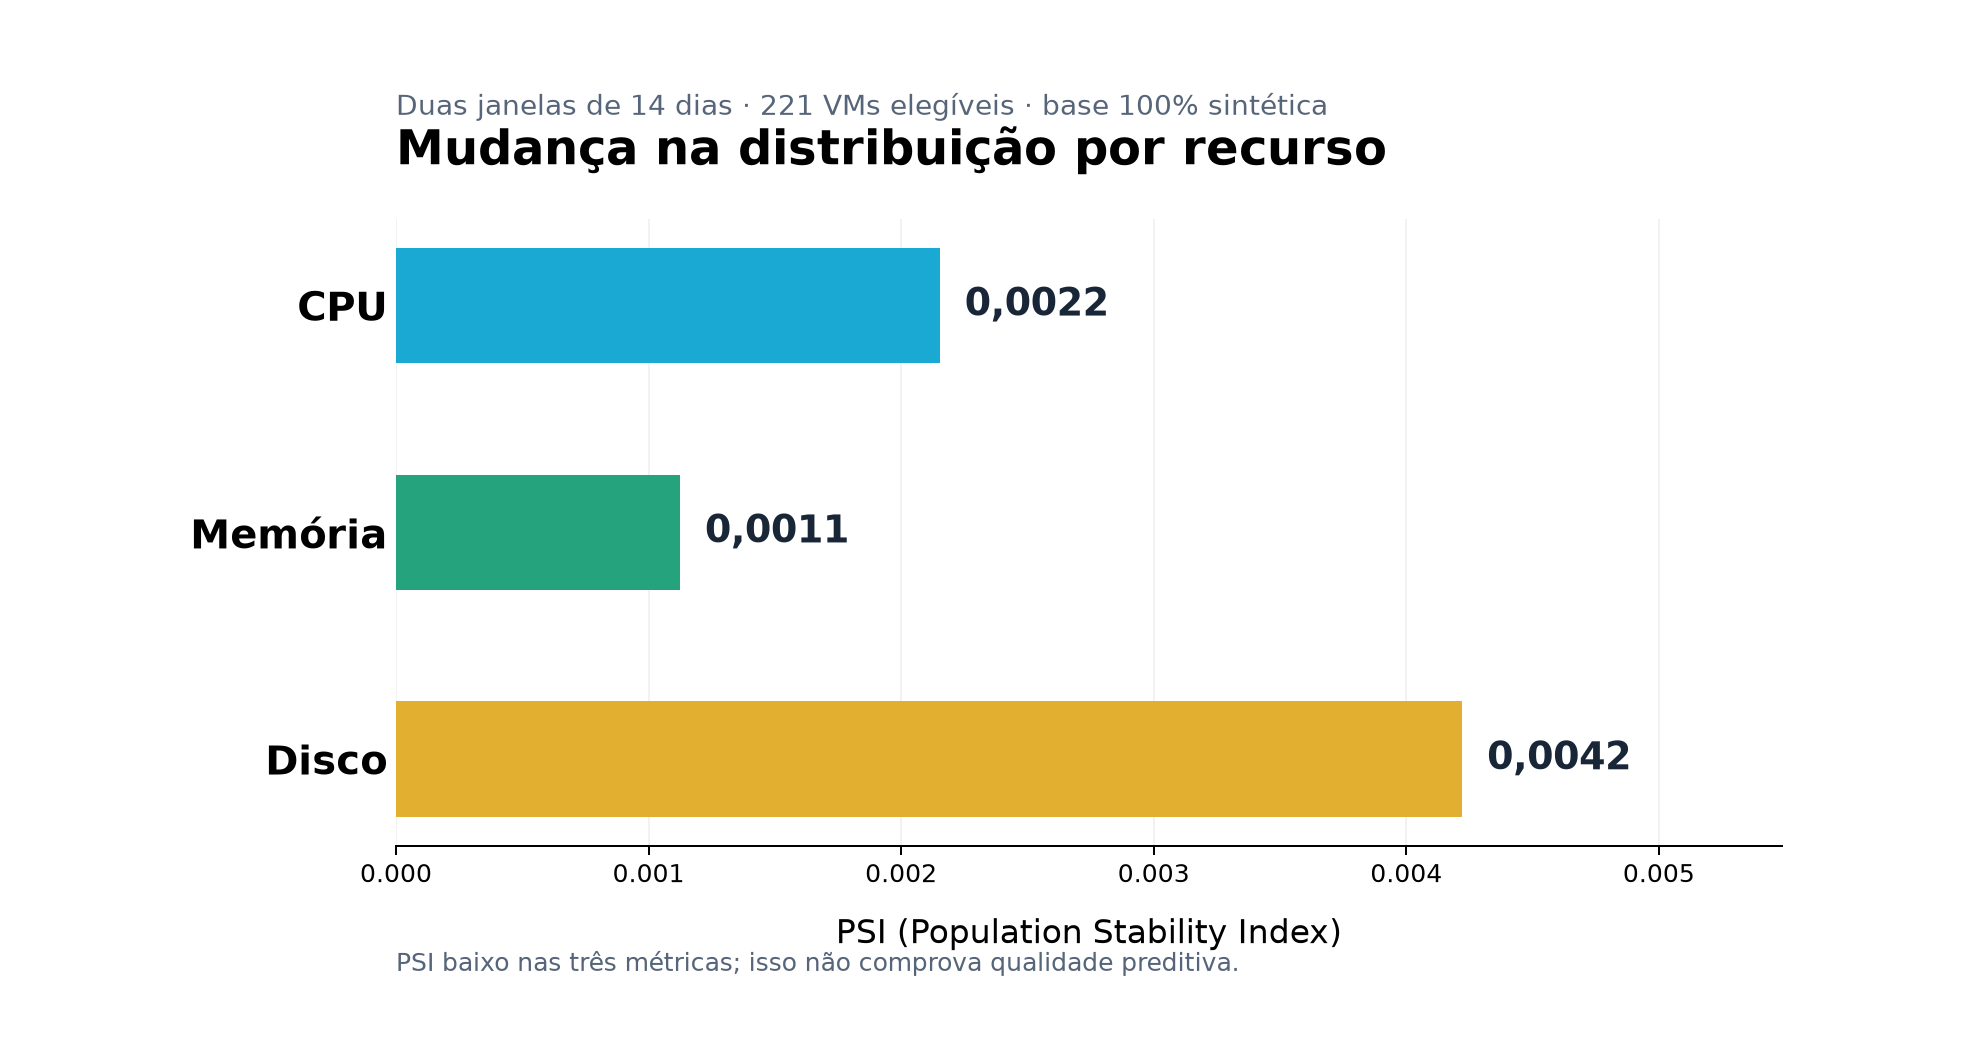

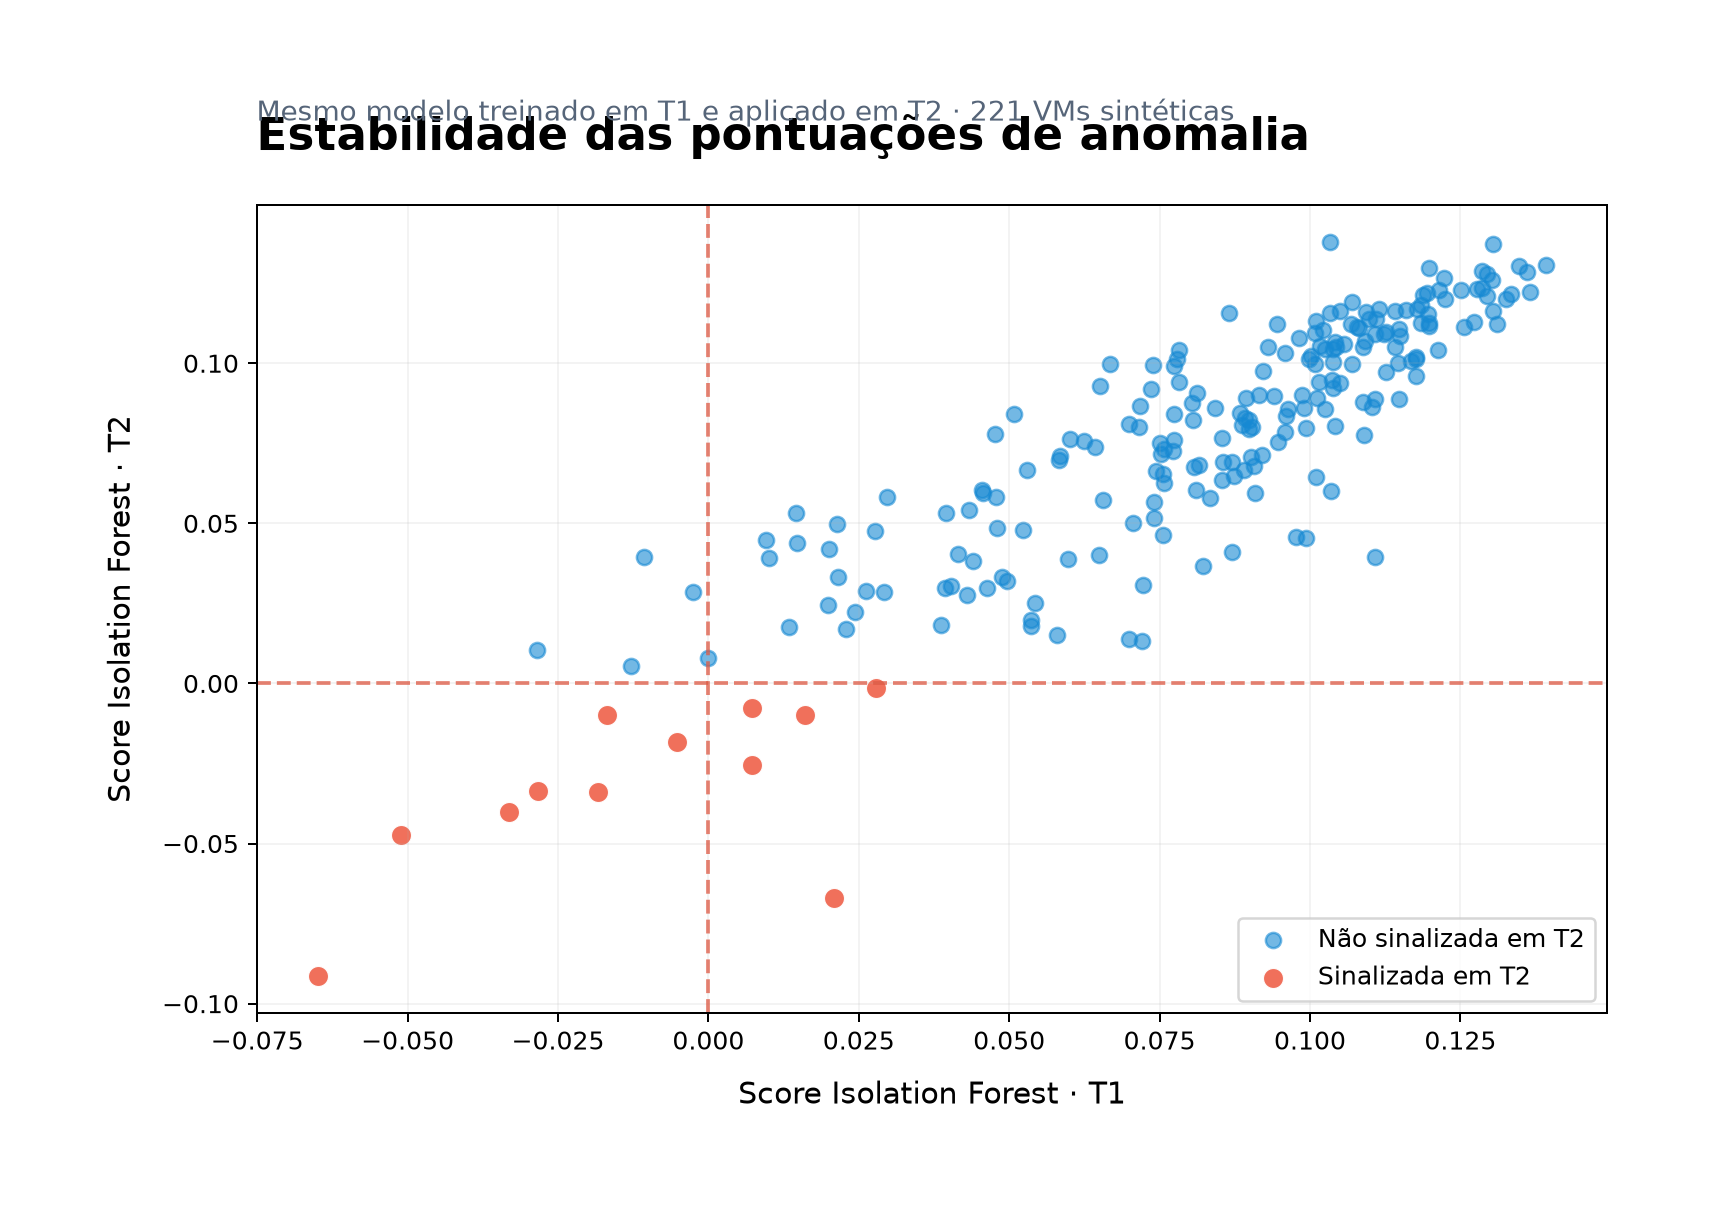

In [4]:
from IPython.display import display, Image
display(Image(filename=str(root/"posts"/"aiops05"/"resultados"/"psi_recursos.png")))
display(Image(filename=str(root/"posts"/"aiops05"/"resultados"/"scores_isolation_forest.png")))

## 5. Interpretação e limites
- **Mudança de distribuição:** PSI/KS são sinais para aprofundar a investigação.
- **Estabilidade do detector:** comparar scores e conjuntos de VMs marcadas mostra mudança de saídas, não precisão ou recall.
- **Concept drift:** exigiria definição do alvo e novos rótulos ou evidências de degradação do desempenho.
- **Próxima investigação:** checar janela de coleta, composição da carga, capacidade adicionada e persistência da mudança.

**Nenhum retreinamento automático ou alteração de VM é executado.**